In [1]:
print("hola")

hola


In [6]:
import torch
#################################### For Image ####################################
from PIL import Image
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor

In [7]:
model = build_sam3_image_model()
processor = Sam3Processor(model)

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.pt:   0%|          | 0.00/3.45G [00:00<?, ?B/s]

In [37]:
image = Image.open("D:\\tesis_dev\\result1\\transforms/gt_crops/crops/ID0006/S05/c003/c003_000364_True.jpg")
inference_state = processor.set_image(image)

In [38]:
output = processor.set_text_prompt(state=inference_state, prompt="Person")

In [39]:
masks, boxes, scores = output["masks"], output["boxes"], output["scores"]

In [40]:
from sam3.visualization_utils import draw_box_on_image, normalize_bbox, plot_results

found 1 object(s)


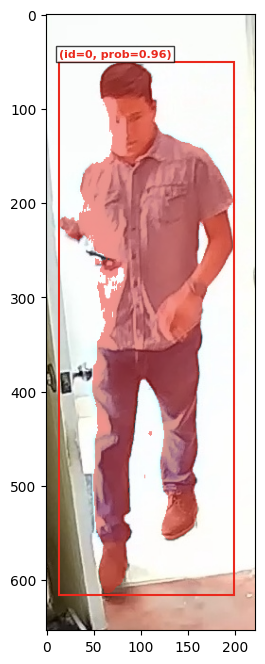

In [41]:
plot_results(image, inference_state)

In [42]:
output

{'original_height': 654,
 'original_width': 222,
 'backbone_out': {'vision_features': tensor([[[[-1.7223e-01, -3.7146e-01, -1.9580e-01,  ..., -1.1285e+00,
             -1.0229e+00, -5.3895e-01],
            [-3.8251e-01, -6.4987e-01, -4.1444e-01,  ..., -1.1607e+00,
             -1.4562e+00, -8.5561e-01],
            [-1.2806e-01, -6.4294e-01, -6.6342e-01,  ..., -7.3609e-01,
             -1.2294e+00, -7.1228e-01],
            ...,
            [-5.0711e-01, -5.2159e-01, -5.3985e-01,  ...,  3.0844e-01,
             -6.0793e-01,  9.1123e-02],
            [-5.9629e-02, -1.0575e-02, -2.8768e-01,  ..., -6.2612e-01,
             -5.7857e-01, -2.4390e-01],
            [ 1.6886e-01,  3.5824e-01,  9.3938e-02,  ..., -4.7153e-01,
             -1.0813e-01, -1.6716e-01]],
  
           [[-1.8963e-01,  1.5193e-01,  8.7642e-02,  ...,  2.6043e-01,
              3.3727e-01,  1.2760e-01],
            [-5.5875e-02,  7.1478e-01,  7.1273e-01,  ...,  4.0620e-01,
              7.3485e-01,  8.5616e-01],
       

In [43]:
len(masks)

1

In [44]:
mask = masks[0].squeeze(0).cpu()

In [45]:
import numpy as np
im_h, im_w = mask.shape
mask_img = np.zeros((im_h, im_w, 4), dtype=np.float32)

In [46]:
mask_img

array([[[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       ...,

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        ...,
        [0., 0., 0., 0.],
        [0., 0.

In [47]:
import numpy as np
import torch
from PIL import Image

# mask: Tensor (H, W) o (1, H, W)
m = mask
if m.ndim == 3:
    m = m.squeeze(0)

# Asegura en CPU y a numpy
m = m.detach().cpu()

binary = (m > 0).to(torch.uint8) * 255  # 0/1 -> 0/255
binary_np = binary.numpy()

Image.fromarray(binary_np, mode="L").save("mask_binaria.png")